# Homework

## Extract the image paths

In [1]:
from extract_image_paths import get_image_paths

image_paths = get_image_paths()
print(len(image_paths))
image_paths[:3]

342878


['/home/grzeg/studia/MLOps/MLOps_course_AGH/lab04/hom4/data/images/small/46/4689906d.png',
 '/home/grzeg/studia/MLOps/MLOps_course_AGH/lab04/hom4/data/images/small/0c/0cd7596c.jpg',
 '/home/grzeg/studia/MLOps/MLOps_course_AGH/lab04/hom4/data/images/small/e6/e602a9af.jpg']

## Model Selection and Understanding

### 3. Vector length and model type

In [2]:
import json

from huggingface_hub import HfApi, hf_hub_download

MODEL_REPO = "sentence-transformers/clip-ViT-B-32"

model_info = HfApi().model_info(MODEL_REPO)
print("pipeline:", model_info.pipeline_tag)
print("tags:", model_info.tags)

with open(hf_hub_download(MODEL_REPO, "0_CLIPModel/config.json")) as f:
    config = json.load(f)

print("architecture:", config["architectures"])
print("vector length (projection_dim):", config["projection_dim"])
print("vision encoder:", {k: config["vision_config"][k] for k in ["image_size", "patch_size", "hidden_size", "num_hidden_layers"]})

pipeline: sentence-similarity
tags: ['sentence-transformers', 'safetensors', 'feature-extraction', 'sentence-similarity', 'arxiv:2103.00020', 'endpoints_compatible', 'deploy:azure', 'region:us']
architecture: ['CLIPModel']
vector length (projection_dim): 512
vision encoder: {'image_size': 224, 'patch_size': 32, 'hidden_size': 768, 'num_hidden_layers': 12}


### Questions

**What is the vector size produced by clip-ViT-B-32?**

512

**What type of model is it?**

A multimodal (text + image)

**What do ViT, B and 32 mean in the model name?**

- ViT - Vision Transformer, the architecture of the image encoder
- B - Base the model size (12 layers, hidden size 768)
- 32 - patch size, the 224x224 input image is split into 32x32 pixel patches

## Database setup

### 1. Postgres with pgvectorscale

In [3]:
%%bash
docker compose -f ../vectorscale_db/docker-compose.yml up -d

docker exec -i vectorscaledb psql -U postgres <<'SQL'
SELECT 'CREATE DATABASE homework_db'
WHERE NOT EXISTS (SELECT FROM pg_database WHERE datname = 'homework_db')\gexec

\c homework_db

CREATE EXTENSION IF NOT EXISTS vectorscale CASCADE;

\dx
SQL

 Container vectorscaledb  Running


You are now connected to database "homework_db" as user "postgres".
CREATE EXTENSION


NOTICE:  extension "vectorscale" already exists, skipping


                                                    List of installed extensions
        Name         | Version |   Schema   |                                      Description                                      
---------------------+---------+------------+---------------------------------------------------------------------------------------
 plpgsql             | 1.0     | pg_catalog | PL/pgSQL procedural language
 timescaledb         | 2.31.0  | public     | Enables scalable inserts and complex queries for time-series data (Community Edition)
 timescaledb_toolkit | 1.26.0  | public     | Library of analytical hyperfunctions, time-series pipelining, and other SQL utilities
 vector              | 0.8.7   | public     | vector data type and ivfflat and hnsw access methods
 vectorscale         | 0.9.1   | public     | diskann access method for vector search
(5 rows)



### 2. Connect with SQLAlchemy

In [4]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="homework_db"
)

engine = create_engine(db_url)

### 3. Table definition

In [ ]:
from pgvector.sqlalchemy import Vector
from sqlalchemy import String
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column


class Base(DeclarativeBase):
    pass


class Img(Base):
    __tablename__ = "images"
    __table_args__ = {'extend_existing': True}

    VECTOR_LENGTH: int = 512

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(512))
    embedding: Mapped[list[float]] = mapped_column(Vector(VECTOR_LENGTH))


Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)

## Image vectorization

In [ ]:
from itertools import islice

import joblib
import torch
from PIL import Image
from sentence_transformers import SentenceTransformer
from sqlalchemy.orm import Session
from tqdm.notebook import tqdm

MAX_IMAGES = 10000
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("clip-ViT-B-32", device=device)


def batched(iterable, n):
    iterator = iter(iterable)
    while batch := list(islice(iterator, n)):
        yield batch


def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()


def vectorize_images(engine, model, image_paths):
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths[:MAX_IMAGES], BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]
            embeddings = model.encode(images)
            imgs = [Img(image_path=path, embedding=embedding) for path, embedding in zip(images_paths_batch, embeddings)]
            insert_images(engine, imgs)
            pbar.update(len(imgs))


vectorize_images(engine, model, image_paths)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


  0%|          | 0/10000 [00:00<?, ?it/s]

## Search and results display

In [7]:
import matplotlib.pyplot as plt
from sqlalchemy import select


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        self.display_images(found_images)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description)

        with Session(self.engine) as session:
            query = (
                select(Img.image_path)
                .order_by(Img.embedding.cosine_distance(image_embedding))
                .limit(k)
            )
            result = session.execute(query).scalars().all()
            session.commit()
        return result

    def display_images(self, images):
        fig, axes = plt.subplots(1, len(images), figsize=(15, 5), squeeze=False)

        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[0][i].imshow(img)
            axes[0][i].axis("off")
            axes[0][i].set_title(f"Image {i+1}")

        plt.show()


image_search = ImageSearch(engine, model)

### 1. Different queries

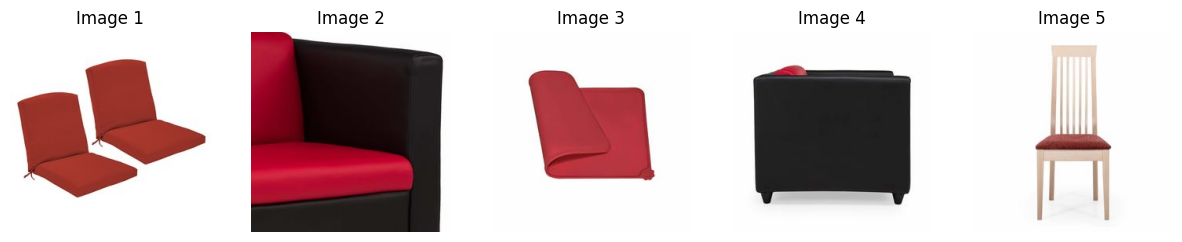

In [8]:
image_search("a red chair", k=5)

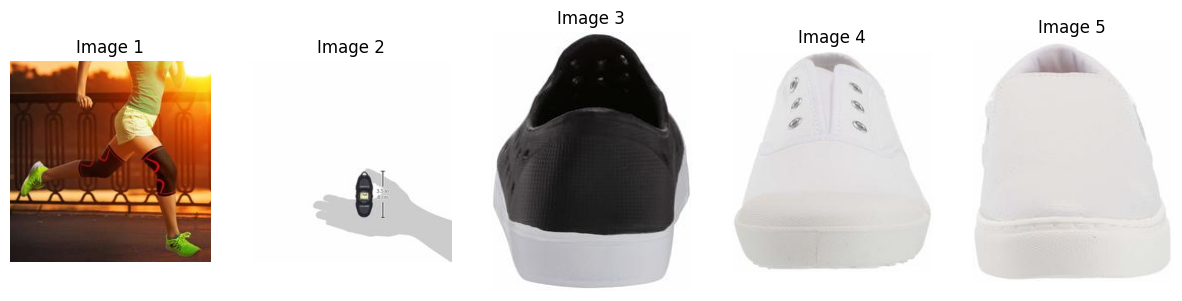

In [9]:
image_search("running shoes", k=5)

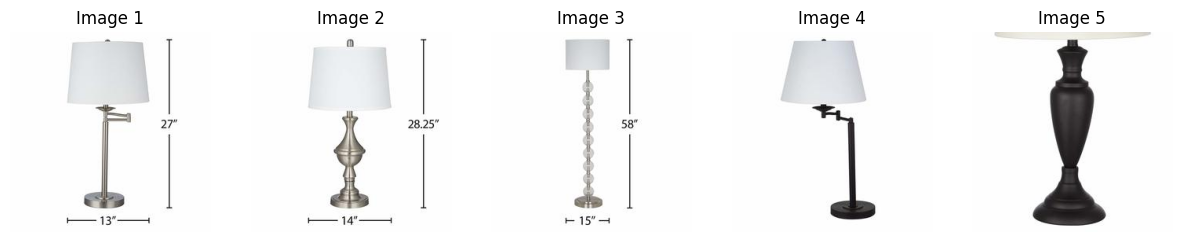

In [10]:
image_search("a table lamp", k=5)

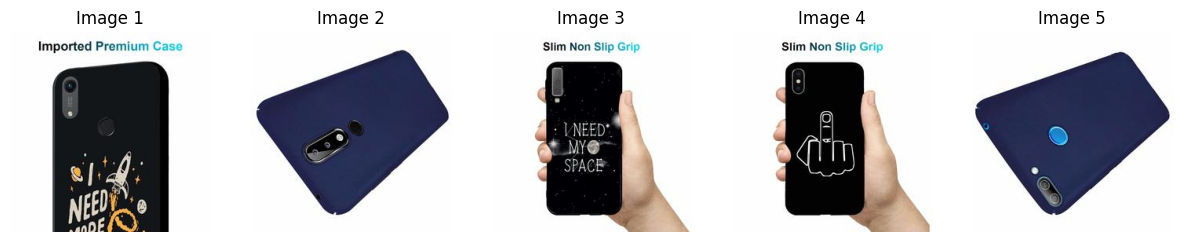

In [11]:
image_search("a smartphone case", k=5)

### Wyniki są ok 

### 2. Different MAX_IMAGES sizes

In [12]:
def reset_table():
    Base.metadata.drop_all(engine)
    Base.metadata.create_all(engine)

#### MAX_IMAGES = 1 000

In [ ]:
MAX_IMAGES = 1000
reset_table()
vectorize_images(engine, model, image_paths)

  0%|          | 0/1000 [00:00<?, ?it/s]

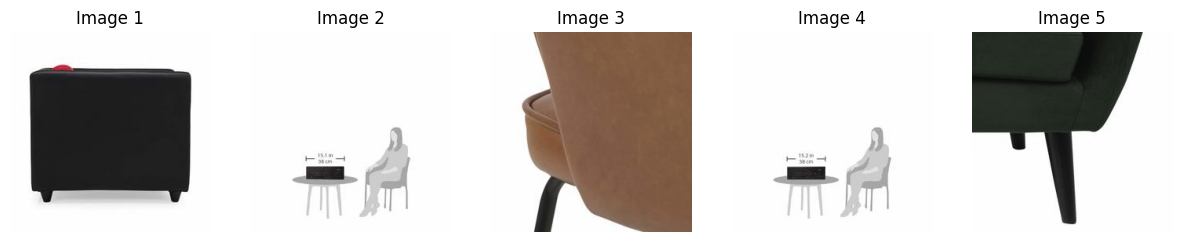

In [14]:
image_search("a red chair", k=5)

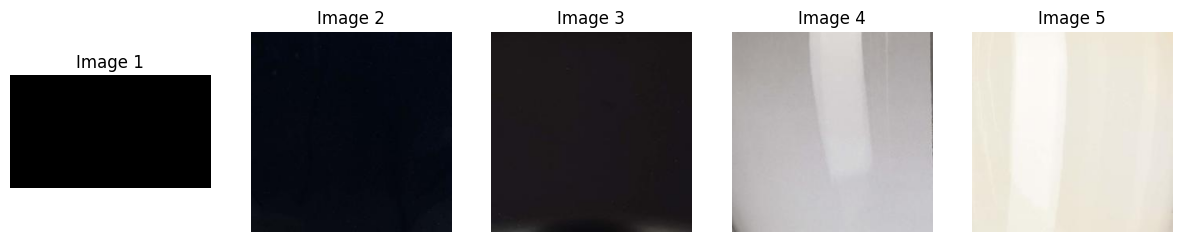

In [15]:
image_search("running shoes", k=5)

#### MAX_IMAGES = 10 000

In [ ]:
MAX_IMAGES = 10000
reset_table()
vectorize_images(engine, model, image_paths)

  0%|          | 0/10000 [00:00<?, ?it/s]

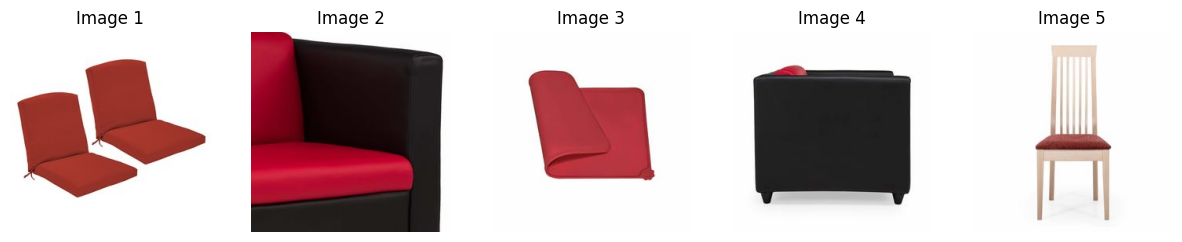

In [17]:
image_search("a red chair", k=5)

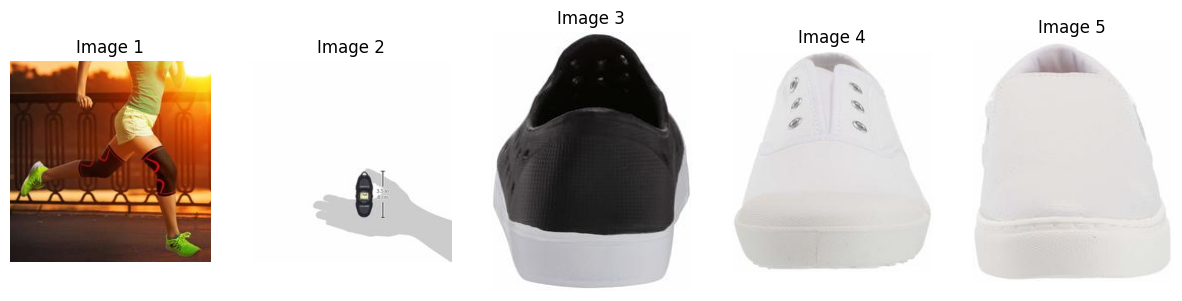

In [18]:
image_search("running shoes", k=5)

#### MAX_IMAGES = 50 000

In [ ]:
MAX_IMAGES = 50000
reset_table()
vectorize_images(engine, model, image_paths)

  0%|          | 0/50000 [00:00<?, ?it/s]

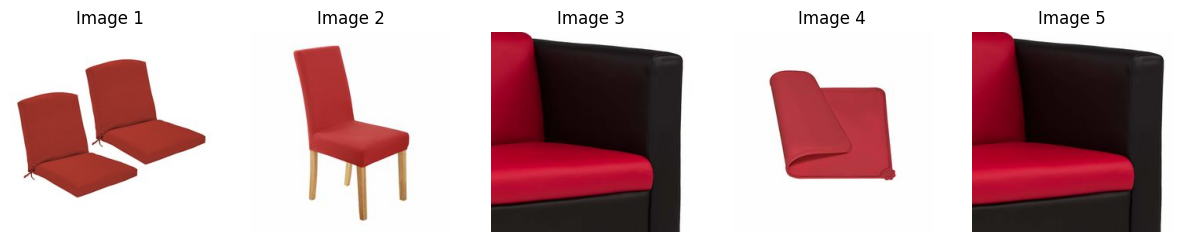

In [20]:
image_search("a red chair", k=5)

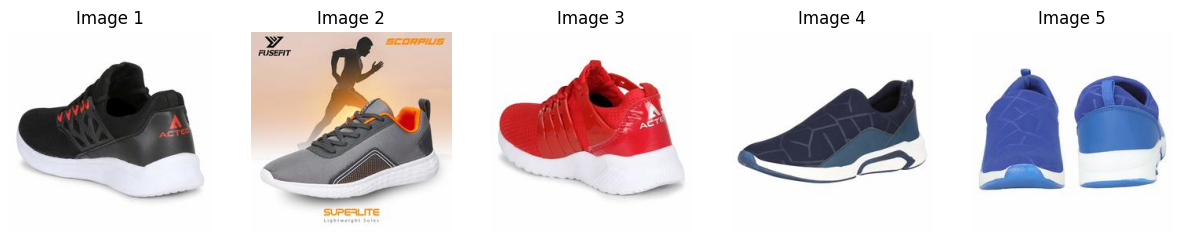

In [21]:
image_search("running shoes", k=5)

### Nawet wyłapało dobrze buty przy MAX_IMAGES = 50000. A przy mniejszym jakoś wyraźnie spadła. Widać różnice